# Klasifikasi dengan Skip-gram vs TF-IDF

Notebook ini membangun **Skip-gram dari nol dengan numpy** lalu menerapkannya ke **seluruh 200 dokumen** untuk klasifikasi, dan membandingkannya dengan TF-IDF.

**Alur:**

```
200 dokumen bersih
   |  1. Tokenisasi
   |  2. Vocabulary (word2idx, idx2word)
   |  3. Pasangan (target, context) dari window
   |  4. Konsep one-hot + inisialisasi bobot W1, W2
   |  5. Training: forward -> softmax -> loss -> gradien -> update
   |  6. Embedding = W1  ->  vektor dokumen = rata-rata vektor kata
   |  7. Klasifikasi Naive Bayes: Skip-gram vs TF-IDF
   |  8. Eksperimen window & vector_size
   |  9. Grid Search
   | 10. Simpan model (joblib)
```

**Catatan teknis:** one-hot literal untuk semua pasangan butuh memori sangat besar (ukuran = jumlah pasangan x jumlah kata unik). Karena itu konsepnya didemokan kecil dulu, sedangkan komputasi aslinya memakai *index lookup* (`W1[idx]`) yang hasilnya **identik** dengan `one_hot @ W1`, ditambah *mini-batch*.

## 0. Import Library & Muat Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib

In [2]:
df = pd.read_excel("../data/dataset_berita_200_bersih.xlsx")
print("Dataset dimuat:", df.shape)

Dataset dimuat: (200, 4)


In [3]:
df[["id", "label"]].head(3)

,id,label
0,1,sport
1,2,sport
2,3,sport


## 1. Tokenisasi

`teks_bersih` sudah dipisah spasi dari tahap Preprocessing, jadi tinggal di-`split()` menjadi daftar kata per dokumen.

In [4]:
daftar_token = [teks.split() for teks in df["teks_bersih"]]

In [5]:
print("Jumlah dokumen:", len(daftar_token))
print("Dokumen 0 (10 kata awal):", daftar_token[0][:10])

Jumlah dokumen: 200
Dokumen 0 (10 kata awal): ['chef', 'de', 'mission', 'cdm', 'indonesia', 'todotua', 'pasaribu', 'terus', 'memonitoring', 'kondisi']


## 2. Vocabulary

Langkah: hitung frekuensi kata, buang kata yang terlalu jarang (`min_count`), lalu beri setiap kata sebuah nomor (indeks).

In [6]:
frekuensi = Counter()
for dok in daftar_token:
    frekuensi.update(dok)

In [7]:
print("Kata unik (sebelum disaring):", len(frekuensi))
print("10 kata paling sering:", frekuensi.most_common(10))

Kata unik (sebelum disaring): 8121
10 kata paling sering: [('yang', 1453), ('dan', 1316), ('di', 1299), ('ini', 722), ('untuk', 693), ('dari', 635), ('dengan', 628), ('dalam', 527), ('juga', 480), ('pada', 444)]


In [8]:
MIN_COUNT = 2
vocab = sorted(k for k, f in frekuensi.items() if f >= MIN_COUNT)
V = len(vocab)
print("Ukuran vocabulary V (frekuensi >= 2):", V)

Ukuran vocabulary V (frekuensi >= 2): 4697


In [9]:
word2idx = {kata: i for i, kata in enumerate(vocab)}
idx2word = {i: kata for kata, i in word2idx.items()}

In [10]:
print("Contoh word2idx:", list(word2idx.items())[:5])

Contoh word2idx: [('10k', 0), ('1s', 1), ('3s', 2), ('3x3', 3), ('3x3a', 4)]


Ubah setiap dokumen dari daftar kata menjadi daftar indeks (kata yang tidak ada di vocabulary dibuang).

In [11]:
dokumen_idx = [[word2idx[k] for k in dok if k in word2idx] for dok in daftar_token]

In [12]:
print("Dokumen 0 sebagai indeks:", dokumen_idx[0][:10])

Dokumen 0 sebagai indeks: [2778, 682, 1489, 4439, 3039, 4393, 2430, 1984, 841, 2842]


## 3. Pasangan (Target, Context) dengan Window

Untuk setiap kata target, kata-kata di sekitarnya dalam jarak `window` menjadi context. Skip-gram belajar **memprediksi context dari target**.

In [13]:
def buat_pasangan(dokumen_idx, window):
    target, konteks = [], []
    for dok in dokumen_idx:
        for i, t in enumerate(dok):
            awal = max(0, i - window)
            akhir = min(len(dok), i + window + 1)
            for j in range(awal, akhir):
                if j != i:
                    target.append(t)
                    konteks.append(dok[j])
    return np.array(target), np.array(konteks)

Demo kecil pada 5 kata pertama dokumen 0 (window=2):

In [14]:
t_demo, c_demo = buat_pasangan([dokumen_idx[0][:5]], window=2)
for a, b in zip(t_demo, c_demo):
    print(f"{idx2word[a]:>15} -> {idx2word[b]}")

        mission -> cdm
        mission -> indonesia
            cdm -> mission
            cdm -> indonesia
            cdm -> todotua
      indonesia -> mission
      indonesia -> cdm
      indonesia -> todotua
      indonesia -> pasaribu
        todotua -> cdm
        todotua -> indonesia
        todotua -> pasaribu
       pasaribu -> indonesia
       pasaribu -> todotua


Sekarang untuk seluruh 200 dokumen (window=2):

In [15]:
WINDOW = 2
target, konteks = buat_pasangan(dokumen_idx, WINDOW)
print("Jumlah pasangan (target, context):", len(target))

Jumlah pasangan (target, context): 247936


## 4. One-Hot (Konsep) & Inisialisasi Bobot

- **W1** (V x D): matriks embedding. Baris ke-`i` = vektor kata ke-`i`. Inilah hasil akhir yang kita pakai.
- **W2** (D x V): matriks output untuk memprediksi context.

In [16]:
D = 50
rng = np.random.default_rng(42)
W1 = rng.normal(0, 0.1, (V, D))
W2 = rng.normal(0, 0.1, (D, V))
print("W1:", W1.shape, "| W2:", W2.shape)

W1: (4697, 50) | W2: (50, 4697)


**Demo one-hot:** vektor berisi nol semua, hanya satu posisi bernilai 1 (posisi kata tersebut).

In [17]:
idx_demo = target[0]
x_onehot = np.zeros(V)
x_onehot[idx_demo] = 1
print("Kata:", idx2word[idx_demo], "| indeks:", idx_demo)
print("Panjang vektor one-hot:", len(x_onehot), "| jumlah elemen bernilai 1:", int(x_onehot.sum()))

Kata: mission | indeks: 2778
Panjang vektor one-hot: 4697 | jumlah elemen bernilai 1: 1


**Kenapa tidak dipakai langsung?** Hitung memori jika semua pasangan dijadikan one-hot:

In [18]:
memori_gb = len(target) * V * 8 / 1e9
print(f"One-hot semua pasangan butuh sekitar {memori_gb:.1f} GB")

One-hot semua pasangan butuh sekitar 9.3 GB


**Trik:** mengalikan one-hot dengan W1 sama saja dengan mengambil satu baris W1. Buktinya:

In [19]:
hasil_matmul = x_onehot @ W1
hasil_lookup = W1[idx_demo]
print("Hasil sama persis?", np.allclose(hasil_matmul, hasil_lookup))

Hasil sama persis? True


## 5. Training Skip-gram

Kita jalankan **satu langkah training** dulu (satu mini-batch), tiap bagian di sel terpisah.

**5.1 Fungsi softmax** (mengubah skor menjadi probabilitas yang jumlahnya 1)

In [20]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)   # stabilitas numerik
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

**5.2 Ambil satu mini-batch** (256 pasangan acak)

In [21]:
UKURAN_BATCH = 256
ids = rng.permutation(len(target))[:UKURAN_BATCH]
t, c = target[ids], konteks[ids]
B = len(ids)
print("Batch target:", t.shape, "| batch context:", c.shape)

Batch target: (256,) | batch context: (256,)


**5.3 Forward pass:** ambil vektor target (hidden layer `h`), hitung skor ke semua kata, ubah jadi probabilitas

In [22]:
h = W1[t]                 # (B, D)
skor = h @ W2             # (B, V)
probs = softmax(skor)     # (B, V)
print("h:", h.shape, "| skor:", skor.shape, "| jumlah probabilitas baris 0:", probs[0].sum().round(4))

h: (256, 50) | skor: (256, 4697) | jumlah probabilitas baris 0: 1.0


**5.4 Loss (cross-entropy):** seberapa kecil probabilitas yang diberikan model pada context yang benar

In [23]:
loss = -np.mean(np.log(probs[np.arange(B), c] + 1e-9))
print("Loss awal:", round(loss, 4), "| loss acak seharusnya sekitar ln(V) =", round(np.log(V), 4))

Loss awal: 8.4562 | loss acak seharusnya sekitar ln(V) = 8.4547


**5.5 Gradien (backward pass)**

In [24]:
dskor = probs.copy()
dskor[np.arange(B), c] -= 1     # prediksi dikurangi target one-hot
dskor /= B

In [25]:
dW2 = h.T @ dskor      # (D, V)
dh = dskor @ W2.T      # (B, D)
print("dW2:", dW2.shape, "| dh:", dh.shape)

dW2: (50, 4697) | dh: (256, 50)


**5.6 Update bobot** (gradient descent). `np.add.at` dipakai karena satu kata bisa muncul berkali-kali dalam satu batch.

In [26]:
LR = 5.0
W2 -= LR * dW2
np.add.at(W1, t, -LR * dh)

**5.7 Cek:** loss pada batch yang sama seharusnya turun

In [27]:
probs_baru = softmax(W1[t] @ W2)
loss_baru = -np.mean(np.log(probs_baru[np.arange(B), c] + 1e-9))
print(f"Loss sebelum: {loss:.4f} -> sesudah: {loss_baru:.4f}")

Loss sebelum: 8.4562 -> sesudah: 8.4366


### 5.8 Bungkus Jadi Fungsi

Langkah 5.3 sampai 5.6 dikemas jadi dua fungsi kecil, lalu diulang untuk semua mini-batch dan beberapa epoch.

In [28]:
def hitung_gradien(W1, W2, t, c):
    B = len(t)
    h = W1[t]
    probs = softmax(h @ W2)
    loss = -np.mean(np.log(probs[np.arange(B), c] + 1e-9))
    dskor = probs
    dskor[np.arange(B), c] -= 1
    dskor /= B
    return loss, h.T @ dskor, dskor @ W2.T   # loss, dW2, dh

In [29]:
def latih_skipgram(target, konteks, V, D, epochs=5, lr=5.0, ukuran_batch=256, seed=42):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 0.1, (V, D))
    W2 = rng.normal(0, 0.1, (D, V))
    riwayat_loss = []
    for epoch in range(epochs):
        urutan = rng.permutation(len(target))
        total_loss = 0
        for mulai in range(0, len(urutan), ukuran_batch):
            ids = urutan[mulai:mulai + ukuran_batch]
            loss, dW2, dh = hitung_gradien(W1, W2, target[ids], konteks[ids])
            W2 -= lr * dW2
            np.add.at(W1, target[ids], -lr * dh)
            total_loss += loss * len(ids)
        riwayat_loss.append(total_loss / len(urutan))
    return W1, riwayat_loss

**5.9 Latih model baseline** (window=2, D=50)

In [30]:
W1_base, loss_base = latih_skipgram(target, konteks, V, D=50, epochs=5)
for i, l in enumerate(loss_base, 1):
    print(f"Epoch {i}: loss = {l:.4f}")

Epoch 1: loss = 7.9398
Epoch 2: loss = 7.2196
Epoch 3: loss = 6.9456
Epoch 4: loss = 6.7373
Epoch 5: loss = 6.5653


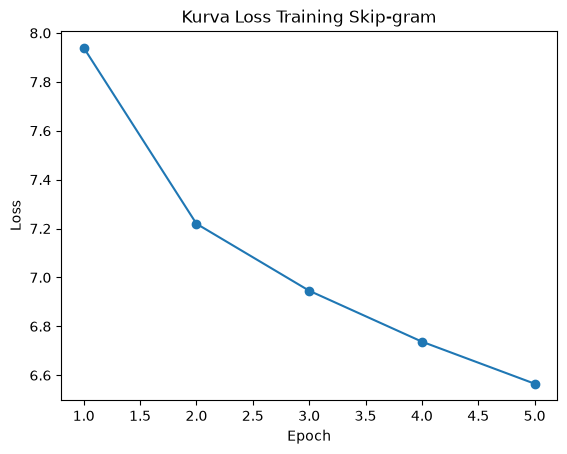

In [31]:
plt.plot(range(1, len(loss_base) + 1), loss_base, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Kurva Loss Training Skip-gram")
plt.show()

**5.10 Cek hasil:** kata-kata yang mirip seharusnya berdekatan (cosine similarity)

In [32]:
def kata_terdekat(kata, W1, n=5):
    v = W1[word2idx[kata]]
    sim = (W1 @ v) / (np.linalg.norm(W1, axis=1) * np.linalg.norm(v) + 1e-9)
    urut = np.argsort(-sim)[1:n + 1]
    return [(idx2word[i], round(float(sim[i]), 3)) for i in urut]

In [33]:
kata_uji = vocab[0]
print("Kata:", kata_uji)
print("Terdekat:", kata_terdekat(kata_uji, W1_base))

Kata: 10k
Terdekat: [('alti', 0.716), ('menggelar', 0.697), ('international', 0.689), ('popprov', 0.654), ('banten', 0.644)]


## 6. Vektor Dokumen (Mean Pooling)

Satu dokumen = rata-rata vektor semua kata di dalamnya, sehingga setiap dokumen punya panjang tetap (D).

In [34]:
def vektor_dokumen(dok_idx, W1):
    if len(dok_idx) == 0:
        return np.zeros(W1.shape[1])
    return W1[dok_idx].mean(axis=0)

In [35]:
X_skipgram = np.array([vektor_dokumen(d, W1_base) for d in dokumen_idx])
print("Ukuran X_skipgram:", X_skipgram.shape)

Ukuran X_skipgram: (200, 50)


## 7. Klasifikasi: Skip-gram vs TF-IDF

Pembagian data latih/uji dibuat sekali dan dipakai untuk kedua representasi supaya perbandingannya adil.

In [36]:
label = df["label"]
indeks_latih, indeks_uji = train_test_split(df.index, test_size=0.2, stratify=label, random_state=42)
y_latih, y_uji = label.loc[indeks_latih], label.loc[indeks_uji]
print("Data latih:", len(indeks_latih), "| Data uji:", len(indeks_uji))

Data latih: 160 | Data uji: 40


**7.1 Skip-gram + GaussianNB**

In [37]:
X_latih_sg, X_uji_sg = X_skipgram[indeks_latih], X_skipgram[indeks_uji]

In [38]:
model_sg = GaussianNB()
model_sg.fit(X_latih_sg, y_latih)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[80.,80.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U7](2,)","['finance','sport']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,2.396e-11
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,50
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 50)","[[-0.19, 0.03,-0.11,...,-0. ,-0.05,-0.13], [-0.36, 0.06, 0.06,...,-0.09, 0.03,-0.03]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 50)","[[0.01,0.01,0. ,...,0. ,0. ,0. ], [0. ,0. ,0.01,...,0. ,0. ,0.01]]"


In [39]:
akurasi_sg = accuracy_score(y_uji, model_sg.predict(X_uji_sg))
print(f"Akurasi Skip-gram: {akurasi_sg:.4f}")

Akurasi Skip-gram: 0.9500


**7.2 TF-IDF + MultinomialNB**

In [40]:
vectorizer_tfidf = TfidfVectorizer(min_df=3)
X_tfidf_full = vectorizer_tfidf.fit_transform(df["teks_bersih"])
print("Ukuran matriks TF-IDF:", X_tfidf_full.shape)

Ukuran matriks TF-IDF: (200, 2556)


In [41]:
X_latih_tfidf, X_uji_tfidf = X_tfidf_full[indeks_latih], X_tfidf_full[indeks_uji]

In [42]:
model_tfidf = MultinomialNB()
model_tfidf.fit(X_latih_tfidf, y_latih)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[80.,80.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U7](2,)","['finance','sport']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 2556)","[[0. ,0. ,0. ,...,0.13,0. ,0.06], [0.56,0.22,0.32,...,0. ,0.38,0.22]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 2556)","[[-8.1 ,-8.1 ,-8.1 ,...,-7.97,-8.1 ,-8.04], [-7.65,-7.89,-7.82,...,-8.1 ,-7.77,-7.9 ]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2556


In [43]:
akurasi_tfidf = accuracy_score(y_uji, model_tfidf.predict(X_uji_tfidf))
print(f"Akurasi TF-IDF: {akurasi_tfidf:.4f}")

Akurasi TF-IDF: 0.9750


**7.3 Ringkasan perbandingan**

In [44]:
ringkasan = pd.DataFrame({
    "Representasi": ["Skip-gram", "TF-IDF"],
    "Jumlah Fitur": [X_skipgram.shape[1], X_tfidf_full.shape[1]],
    "Akurasi": [akurasi_sg, akurasi_tfidf],
})
ringkasan

,Representasi,Jumlah Fitur,Akurasi
0,Skip-gram,50,0.950
1,TF-IDF,2556,0.975


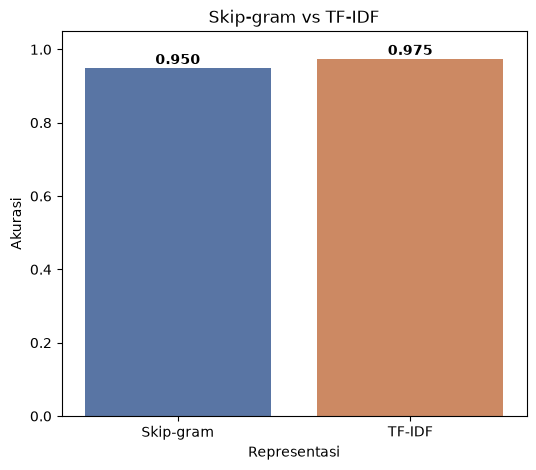

In [45]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(data=ringkasan, x="Representasi", y="Akurasi", hue="Representasi", palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
for i, v in enumerate(ringkasan["Akurasi"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_title("Skip-gram vs TF-IDF")
plt.show()

## 8. Eksperimen `window` dan `vector_size`

- **window**: jarak kata sekitar yang dianggap context.
- **vector_size**: dimensi embedding.

Satu fungsi kecil melakukan seluruh pipeline (pasangan, training, vektor dokumen, klasifikasi) untuk satu kombinasi parameter.

In [46]:
def evaluasi_skipgram(window, vector_size, epochs=5):
    t, c = buat_pasangan(dokumen_idx, window)
    W1, _ = latih_skipgram(t, c, V, vector_size, epochs=epochs)
    X = np.array([vektor_dokumen(d, W1) for d in dokumen_idx])
    clf = GaussianNB().fit(X[indeks_latih], y_latih)
    return accuracy_score(y_uji, clf.predict(X[indeks_uji]))

In [47]:
kombinasi = [(2, 50), (5, 50), (5, 100), (8, 100)]
hasil = []
for w, d in kombinasi:
    akurasi = evaluasi_skipgram(w, d)
    hasil.append({"window": w, "vector_size": d, "akurasi": akurasi})
    print(f"window={w}, vector_size={d} -> akurasi: {akurasi:.4f}")

window=2, vector_size=50 -> akurasi: 0.9500
window=5, vector_size=50 -> akurasi: 0.9750
window=5, vector_size=100 -> akurasi: 0.9500
window=8, vector_size=100 -> akurasi: 0.9750


In [48]:
df_eksperimen = pd.DataFrame(hasil)
df_eksperimen

,window,vector_size,akurasi
0,2,50,0.950
1,5,50,0.975
2,5,100,0.950
3,8,100,0.975


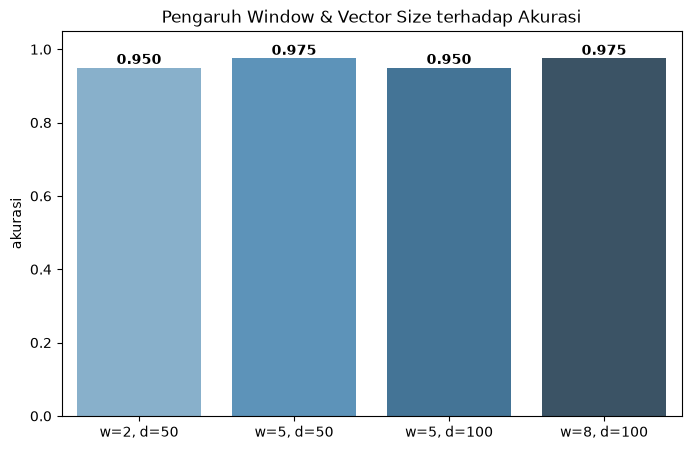

In [49]:
label_kombinasi = [f"w={r.window}, d={r.vector_size}" for r in df_eksperimen.itertuples()]
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=label_kombinasi, y=df_eksperimen["akurasi"], hue=label_kombinasi, palette="Blues_d", legend=False, ax=ax)
for i, v in enumerate(df_eksperimen["akurasi"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_title("Pengaruh Window & Vector Size terhadap Akurasi")
plt.show()

In [50]:
terbaik = df_eksperimen.loc[df_eksperimen["akurasi"].idxmax()]
WINDOW_FINAL = int(terbaik["window"])
VECTOR_SIZE_FINAL = int(terbaik["vector_size"])
print(f"Kombinasi terbaik: window={WINDOW_FINAL}, vector_size={VECTOR_SIZE_FINAL}")

Kombinasi terbaik: window=5, vector_size=50


## 9. Latih Ulang Skip-gram Final (Parameter Terbaik)

In [51]:
target_f, konteks_f = buat_pasangan(dokumen_idx, WINDOW_FINAL)
print("Jumlah pasangan:", len(target_f))

Jumlah pasangan: 616840


In [52]:
W1_final, loss_final = latih_skipgram(target_f, konteks_f, V, VECTOR_SIZE_FINAL, epochs=10)
print("Loss epoch pertama:", round(loss_final[0], 4), "| epoch terakhir:", round(loss_final[-1], 4))

Loss epoch pertama: 7.5674 | epoch terakhir: 6.235


In [53]:
X_skipgram_final = np.array([vektor_dokumen(d, W1_final) for d in dokumen_idx])
model_sg_final = GaussianNB().fit(X_skipgram_final[indeks_latih], y_latih)
pred_sg_final = model_sg_final.predict(X_skipgram_final[indeks_uji])
akurasi_sg_final = accuracy_score(y_uji, pred_sg_final)
print(f"Akurasi Skip-gram final: {akurasi_sg_final:.4f}")

Akurasi Skip-gram final: 0.9750


In [54]:
print(classification_report(y_uji, pred_sg_final))

              precision    recall  f1-score   support

     finance       0.95      1.00      0.98        20
       sport       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



## 10. Grid Search: Hyperparameter Tuning

`GridSearchCV` mencoba semua kandidat parameter dengan cross-validation (cv=5) pada data latih.

**10.1 Tuning `alpha` (smoothing) pada TF-IDF + MultinomialNB**

In [55]:
param_grid_tfidf = {"alpha": [0.01, 0.1, 0.5, 1.0, 2.0]}
grid_tfidf = GridSearchCV(MultinomialNB(), param_grid_tfidf, cv=5, scoring="accuracy")
grid_tfidf.fit(X_latih_tfidf, y_latih)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",MultinomialNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalue

In [56]:
print("Parameter terbaik:", grid_tfidf.best_params_)
print(f"Akurasi CV terbaik: {grid_tfidf.best_score_:.4f}")

Parameter terbaik: {'alpha': 0.01}
Akurasi CV terbaik: 1.0000


In [57]:
model_tfidf_tuned = grid_tfidf.best_estimator_
akurasi_tfidf_tuned = accuracy_score(y_uji, model_tfidf_tuned.predict(X_uji_tfidf))
print(f"Akurasi data uji setelah tuning: {akurasi_tfidf_tuned:.4f} (sebelumnya: {akurasi_tfidf:.4f})")

Akurasi data uji setelah tuning: 0.9500 (sebelumnya: 0.9750)


**10.2 Tuning `var_smoothing` pada Skip-gram + GaussianNB**

In [58]:
param_grid_sg = {"var_smoothing": [1e-12, 1e-9, 1e-6, 1e-3, 1e-1]}
grid_sg = GridSearchCV(GaussianNB(), param_grid_sg, cv=5, scoring="accuracy")
grid_sg.fit(X_skipgram_final[indeks_latih], y_latih)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GaussianNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'var_smoothing': [1e-12, 1e-09, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with hig

In [59]:
print("Parameter terbaik:", grid_sg.best_params_)
print(f"Akurasi CV terbaik: {grid_sg.best_score_:.4f}")

Parameter terbaik: {'var_smoothing': 1e-12}
Akurasi CV terbaik: 1.0000


In [60]:
model_sg_tuned = grid_sg.best_estimator_
akurasi_sg_tuned = accuracy_score(y_uji, model_sg_tuned.predict(X_skipgram_final[indeks_uji]))
print(f"Akurasi data uji setelah tuning: {akurasi_sg_tuned:.4f} (sebelumnya: {akurasi_sg_final:.4f})")

Akurasi data uji setelah tuning: 0.9750 (sebelumnya: 0.9750)


## 11. Simpan Model Terbaik untuk Deployment

In [61]:
print(f"Skip-gram (tuned): {akurasi_sg_tuned:.4f}")
print(f"TF-IDF   (tuned): {akurasi_tfidf_tuned:.4f}")

Skip-gram (tuned): 0.9750
TF-IDF   (tuned): 0.9500


In [62]:
if akurasi_tfidf_tuned >= akurasi_sg_tuned:
    joblib.dump(model_tfidf_tuned, "../data/model_final.joblib")
    joblib.dump(vectorizer_tfidf, "../data/vectorizer_final.joblib")
    print("Disimpan: TF-IDF + MultinomialNB")
else:
    joblib.dump(model_sg_tuned, "../data/model_final.joblib")
    np.save("../data/embedding_W1.npy", W1_final)
    joblib.dump(word2idx, "../data/word2idx.joblib")
    print("Disimpan: Skip-gram manual + GaussianNB (W1 dan word2idx ikut disimpan)")

Disimpan: Skip-gram manual + GaussianNB (W1 dan word2idx ikut disimpan)


## Ringkasan

- Skip-gram dibangun manual dengan numpy: vocabulary, pasangan (target, context), W1 dan W2, softmax, cross-entropy, gradien, update.
- One-hot dijelaskan secara konsep; komputasi memakai index lookup `W1[idx]` (hasil identik dengan `one_hot @ W1`) dan mini-batch agar hemat memori.
- Vektor dokumen = rata-rata vektor kata; dibandingkan dengan TF-IDF pada pembagian data yang sama.
- `window` dan `vector_size` diatur lewat argumen `buat_pasangan(..., window)` dan `latih_skipgram(..., D)`.
- `test_size=0.2`: 20% data jadi data uji; jika total data 300, maka latih 240 dan uji 60.
- Grid Search mencari parameter terbaik secara sistematis dengan cross-validation.